# 🦟 Malaria Cell Classification using MobileNetV2 (Transfer Learning)
### Semester Project | TensorFlow/Keras | Kaggle GPU
---
**Approach:** Transfer learning with MobileNetV2 pretrained on ImageNet.  
**Dataset:** NIH Malaria Cell Images (~27,500 images, balanced binary classification)  
**Goal:** Classify cell images as `Parasitized` (infected) or `Uninfected`

## 1. Import Libraries

In [35]:
import os
import json
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, roc_curve, auc, precision_recall_curve
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# Style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Configuration

In [36]:
# ── Paths ──────────────────────────────────────────────
DATA_DIR = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images'
MODEL_PATH  = 'malaria_mobilenetv2.keras'
HISTORY_PATH = 'training_history.json'

# ── Hyperparameters ─────────────────────────────────────
IMG_SIZE    = (96, 96)      # MobileNetV2 min is 96x96
BATCH_SIZE  = 64            # Larger batch → faster on GPU
EPOCHS_HEAD = 10             # Train only the new head first
EPOCHS_FINE = 45             # Fine-tune last few base layers
LR_HEAD     = 1e-3
LR_FINE     = 1e-5

CLASS_NAMES = ['Parasitized', 'Uninfected']
print("Config ready. Data dir:", DATA_DIR)

Config ready. Data dir: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images


In [37]:
import os

print(os.listdir('/kaggle/input'))

['datasets']


In [38]:
import os

parasitized_imgs = os.listdir(os.path.join(DATA_DIR, 'Parasitized'))
uninfected_imgs  = os.listdir(os.path.join(DATA_DIR, 'Uninfected'))

print(len(parasitized_imgs), len(uninfected_imgs))

13780 13780


## 3. Dataset Exploration & Visualisation

In [39]:
# ── Count images per class ──────────────────────────────
parasitized_imgs = os.listdir(os.path.join(DATA_DIR, 'Parasitized'))
uninfected_imgs  = os.listdir(os.path.join(DATA_DIR, 'Uninfected'))

# Remove non-image files (e.g. Thumbs.db)
exts = ('.png', '.jpg', '.jpeg')
parasitized_imgs = [f for f in parasitized_imgs if f.lower().endswith(exts)]
uninfected_imgs  = [f for f in uninfected_imgs  if f.lower().endswith(exts)]

n_parasitized = len(parasitized_imgs)
n_uninfected  = len(uninfected_imgs)
total         = n_parasitized + n_uninfected

print(f"Parasitized  : {n_parasitized:,} images")
print(f"Uninfected   : {n_uninfected:,} images")
print(f"Total        : {total:,} images")
print(f"Balance ratio: {n_parasitized/n_uninfected:.3f}")

Parasitized  : 13,779 images
Uninfected   : 13,779 images
Total        : 27,558 images
Balance ratio: 1.000


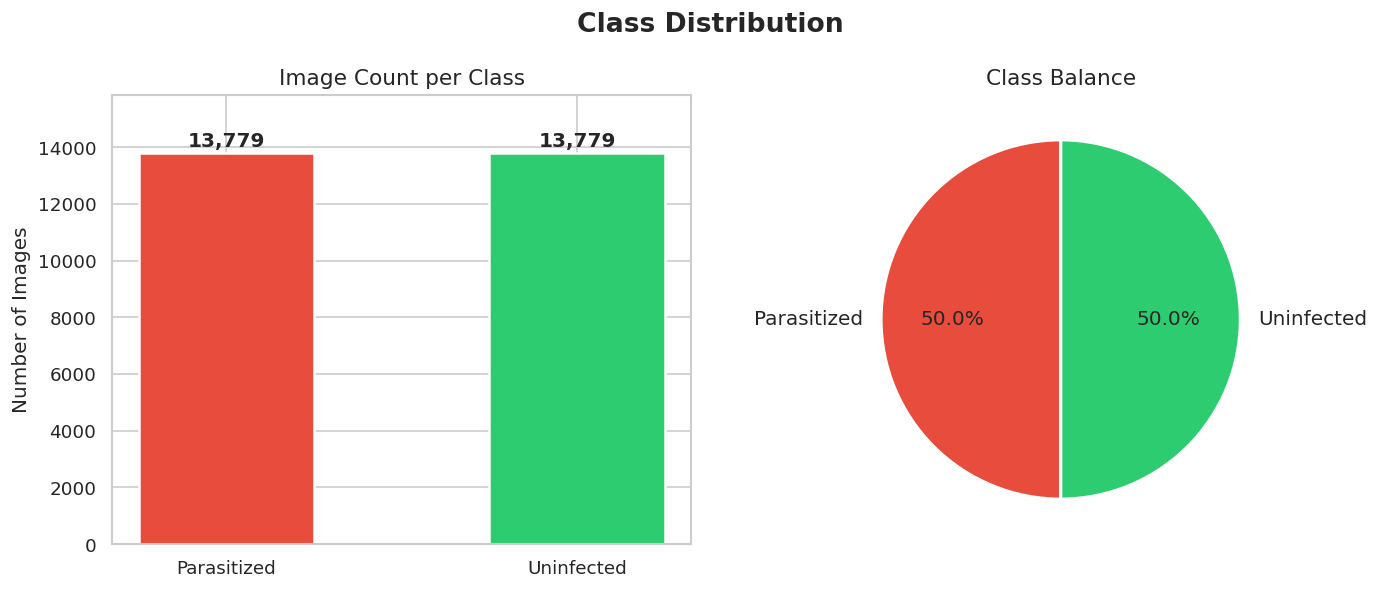

In [40]:
# ── Visualisation 1: Class Distribution (Bar + Pie) ─────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Class Distribution', fontsize=16, fontweight='bold')

colors = ['#E74C3C', '#2ECC71']

# Bar chart
bars = axes[0].bar(['Parasitized', 'Uninfected'], [n_parasitized, n_uninfected],
                   color=colors, edgecolor='white', linewidth=1.5, width=0.5)
axes[0].set_title('Image Count per Class', fontsize=13)
axes[0].set_ylabel('Number of Images')
for bar, val in zip(bars, [n_parasitized, n_uninfected]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold', fontsize=12)
axes[0].set_ylim(0, max(n_parasitized, n_uninfected) * 1.15)

# Pie chart
axes[1].pie([n_parasitized, n_uninfected], labels=['Parasitized', 'Uninfected'],
            colors=colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2},
            textprops={'fontsize': 12})
axes[1].set_title('Class Balance', fontsize=13)

plt.tight_layout()
plt.savefig('viz_class_distribution.png', bbox_inches='tight')
plt.show()

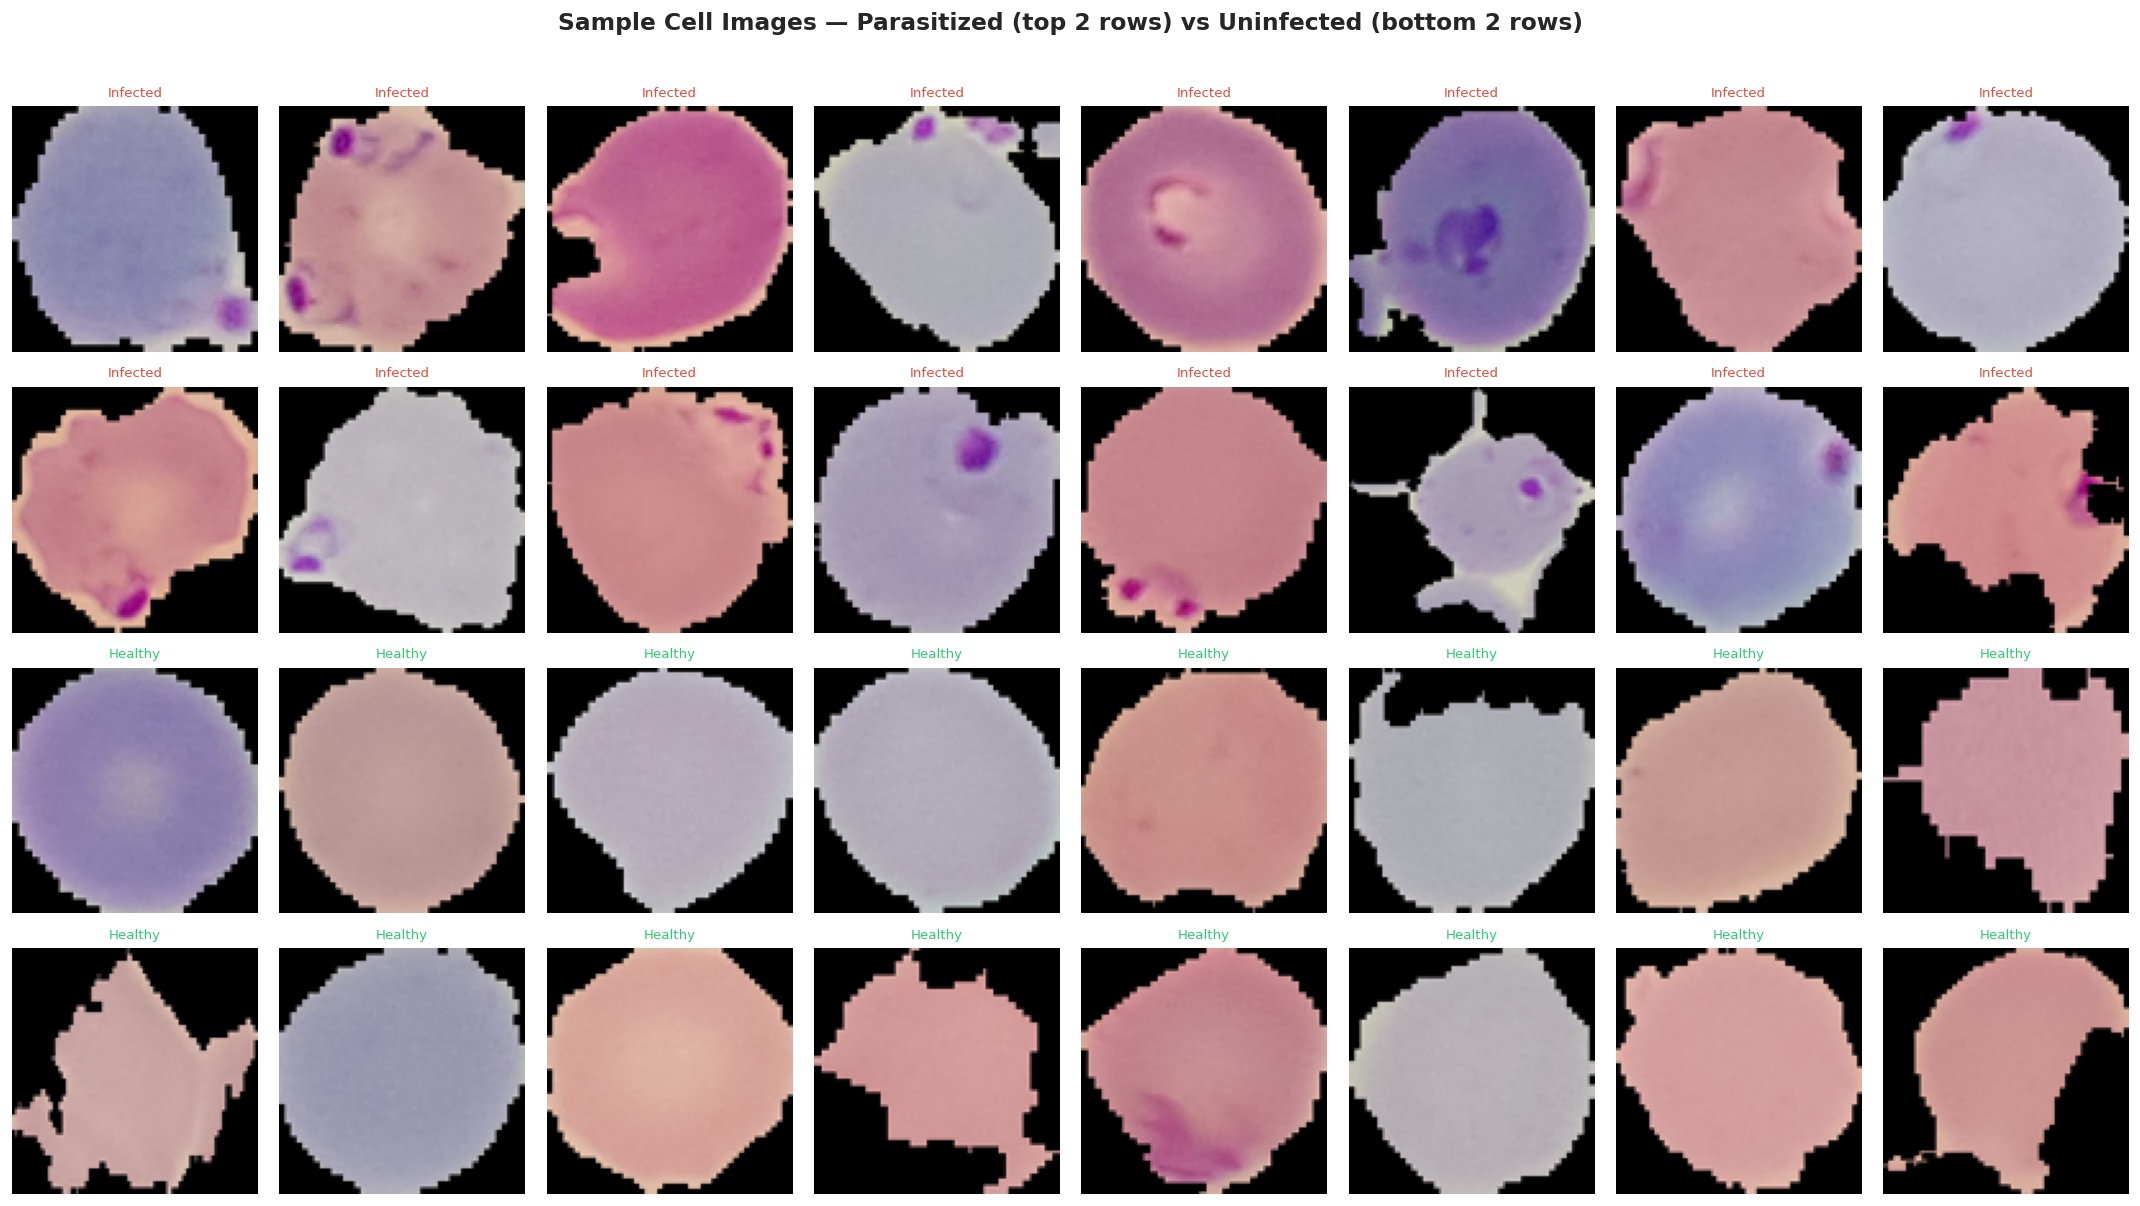

In [41]:
# ── Visualisation 2: Sample Images Grid ─────────────────
fig, axes = plt.subplots(4, 8, figsize=(18, 10))
fig.suptitle('Sample Cell Images — Parasitized (top 2 rows) vs Uninfected (bottom 2 rows)',
             fontsize=14, fontweight='bold', y=1.01)

para_sample   = random.sample(parasitized_imgs, 16)
uninf_sample  = random.sample(uninfected_imgs,  16)

for col, fname in enumerate(para_sample[:8]):
    img = Image.open(os.path.join(DATA_DIR, 'Parasitized', fname)).convert('RGB').resize((96,96))
    axes[0, col].imshow(img); axes[0, col].axis('off')
    axes[0, col].set_title('Infected', color='#E74C3C', fontsize=8)

for col, fname in enumerate(para_sample[8:]):
    img = Image.open(os.path.join(DATA_DIR, 'Parasitized', fname)).convert('RGB').resize((96,96))
    axes[1, col].imshow(img); axes[1, col].axis('off')
    axes[1, col].set_title('Infected', color='#E74C3C', fontsize=8)

for col, fname in enumerate(uninf_sample[:8]):
    img = Image.open(os.path.join(DATA_DIR, 'Uninfected', fname)).convert('RGB').resize((96,96))
    axes[2, col].imshow(img); axes[2, col].axis('off')
    axes[2, col].set_title('Healthy', color='#2ECC71', fontsize=8)

for col, fname in enumerate(uninf_sample[8:]):
    img = Image.open(os.path.join(DATA_DIR, 'Uninfected', fname)).convert('RGB').resize((96,96))
    axes[3, col].imshow(img); axes[3, col].axis('off')
    axes[3, col].set_title('Healthy', color='#2ECC71', fontsize=8)

plt.tight_layout()
plt.savefig('viz_sample_images.png', bbox_inches='tight')
plt.show()

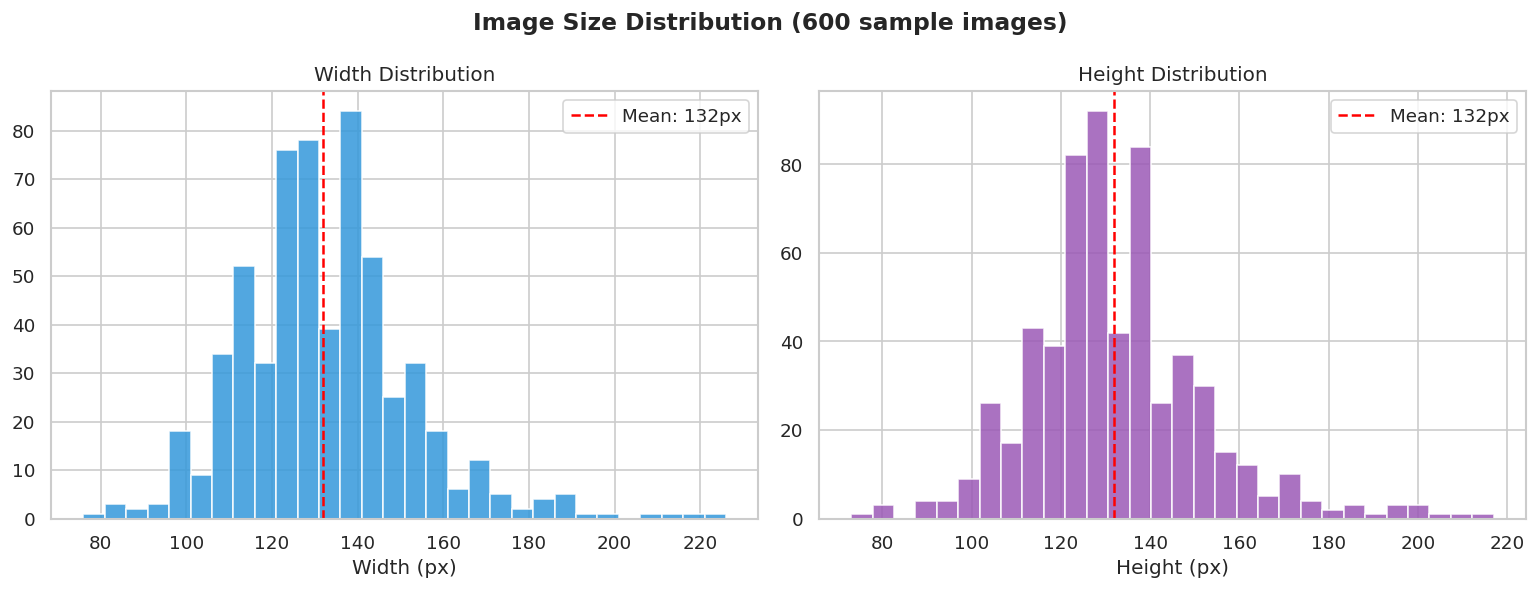

Width  — Min: 76, Max: 226, Mean: 131.9
Height — Min: 73, Max: 217, Mean: 132.0


In [42]:
# ── Visualisation 3: Image Size Distribution ─────────────
widths, heights = [], []
sample_paths = (
    [os.path.join(DATA_DIR, 'Parasitized', f) for f in random.sample(parasitized_imgs, 300)] +
    [os.path.join(DATA_DIR, 'Uninfected',  f) for f in random.sample(uninfected_imgs,  300)]
)
for path in sample_paths:
    try:
        w, h = Image.open(path).size
        widths.append(w); heights.append(h)
    except: pass

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Image Size Distribution (600 sample images)', fontsize=14, fontweight='bold')

axes[0].hist(widths,  bins=30, color='#3498DB', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(widths), color='red', linestyle='--', label=f'Mean: {np.mean(widths):.0f}px')
axes[0].set_title('Width Distribution'); axes[0].set_xlabel('Width (px)'); axes[0].legend()

axes[1].hist(heights, bins=30, color='#9B59B6', edgecolor='white', alpha=0.85)
axes[1].axvline(np.mean(heights), color='red', linestyle='--', label=f'Mean: {np.mean(heights):.0f}px')
axes[1].set_title('Height Distribution'); axes[1].set_xlabel('Height (px)'); axes[1].legend()

plt.tight_layout()
plt.savefig('viz_size_distribution.png', bbox_inches='tight')
plt.show()
print(f"Width  — Min: {min(widths)}, Max: {max(widths)}, Mean: {np.mean(widths):.1f}")
print(f"Height — Min: {min(heights)}, Max: {max(heights)}, Mean: {np.mean(heights):.1f}")

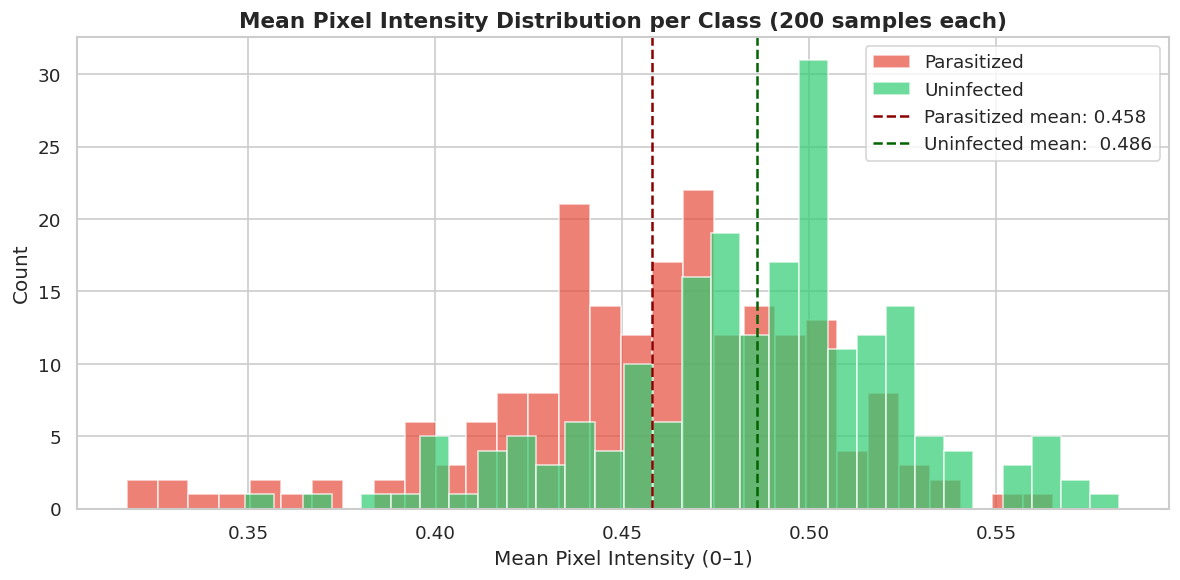

In [43]:
# ── Visualisation 4: Mean Pixel Intensity per Class ──────
def mean_intensity(img_dir, fnames, n=200):
    intensities = []
    for f in random.sample(fnames, n):
        img = np.array(Image.open(os.path.join(img_dir, f)).convert('RGB').resize((96,96))) / 255.0
        intensities.append(img.mean())
    return intensities

p_intensity = mean_intensity(os.path.join(DATA_DIR, 'Parasitized'), parasitized_imgs)
u_intensity = mean_intensity(os.path.join(DATA_DIR, 'Uninfected'),  uninfected_imgs)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(p_intensity, bins=30, alpha=0.7, color='#E74C3C', label='Parasitized', edgecolor='white')
ax.hist(u_intensity, bins=30, alpha=0.7, color='#2ECC71', label='Uninfected',  edgecolor='white')
ax.axvline(np.mean(p_intensity), color='darkred',   linestyle='--', lw=1.5, label=f'Parasitized mean: {np.mean(p_intensity):.3f}')
ax.axvline(np.mean(u_intensity), color='darkgreen', linestyle='--', lw=1.5, label=f'Uninfected mean:  {np.mean(u_intensity):.3f}')
ax.set_title('Mean Pixel Intensity Distribution per Class (200 samples each)', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Pixel Intensity (0–1)'); ax.set_ylabel('Count'); ax.legend()
plt.tight_layout()
plt.savefig('viz_pixel_intensity.png', bbox_inches='tight')
plt.show()

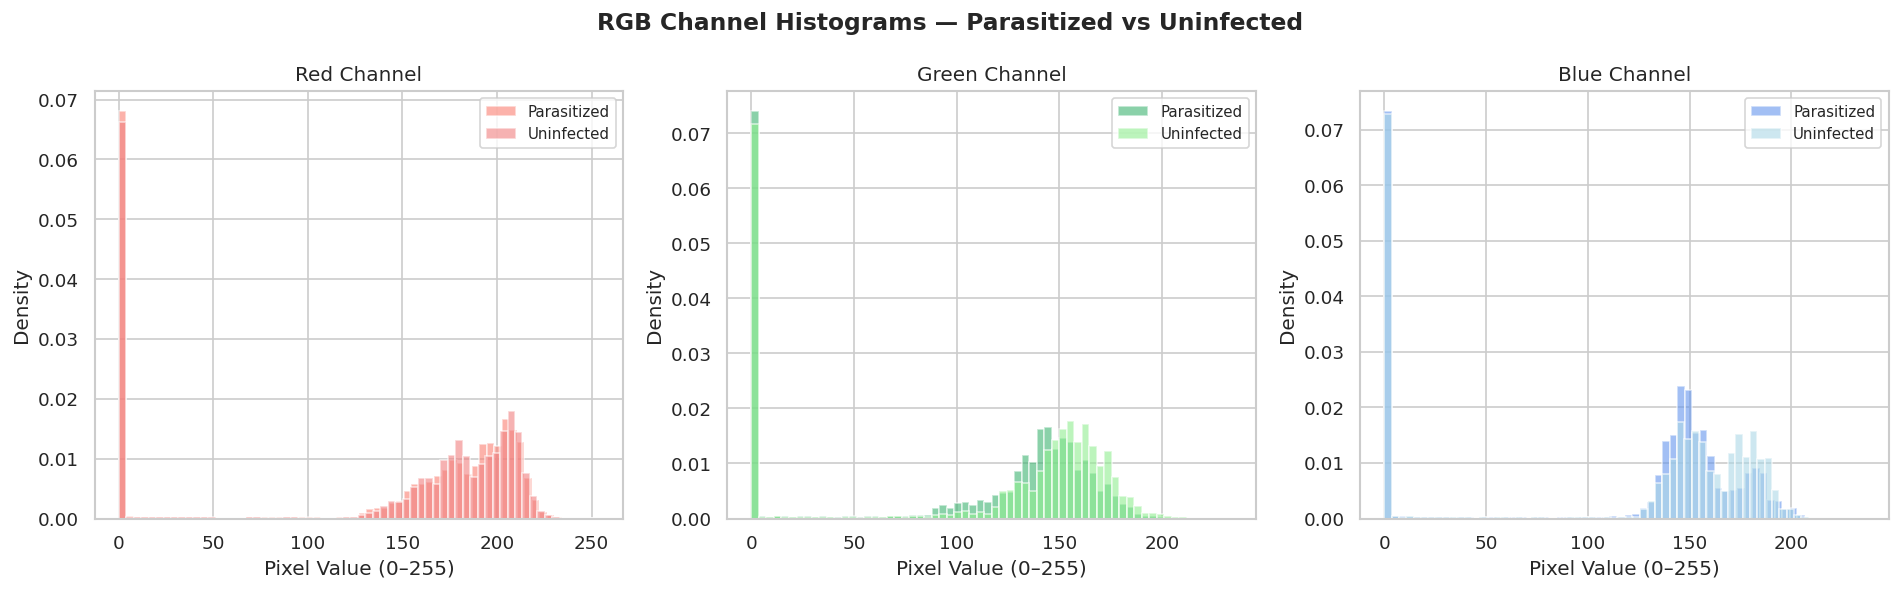

In [44]:
# ── Visualisation 5: RGB Channel Histograms ──────────────
def avg_channel_hist(img_dir, fnames, n=100):
    r_all, g_all, b_all = [], [], []
    for f in random.sample(fnames, n):
        img = np.array(Image.open(os.path.join(img_dir, f)).convert('RGB').resize((96,96)))
        r_all.append(img[:,:,0].flatten())
        g_all.append(img[:,:,1].flatten())
        b_all.append(img[:,:,2].flatten())
    return np.concatenate(r_all), np.concatenate(g_all), np.concatenate(b_all)

p_r, p_g, p_b = avg_channel_hist(os.path.join(DATA_DIR, 'Parasitized'), parasitized_imgs)
u_r, u_g, u_b = avg_channel_hist(os.path.join(DATA_DIR, 'Uninfected'),  uninfected_imgs)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('RGB Channel Histograms — Parasitized vs Uninfected', fontsize=14, fontweight='bold')
channels = [('Red', p_r, u_r, 'salmon', 'lightcoral'),
            ('Green', p_g, u_g, 'mediumseagreen', 'lightgreen'),
            ('Blue', p_b, u_b, 'cornflowerblue', 'lightblue')]

for ax, (name, p_ch, u_ch, cp, cu) in zip(axes, channels):
    ax.hist(p_ch, bins=64, alpha=0.6, color=cp, label='Parasitized', density=True)
    ax.hist(u_ch, bins=64, alpha=0.6, color=cu, label='Uninfected',  density=True)
    ax.set_title(f'{name} Channel'); ax.set_xlabel('Pixel Value (0–255)')
    ax.set_ylabel('Density'); ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('viz_rgb_channels.png', bbox_inches='tight')
plt.show()

## 4. Data Generators (Train / Val / Test)

In [45]:
# ── Augmentation only on train; val/test just rescale ────
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# 80% train
train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    seed=SEED
)

# 20% val (no augmentation)
val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
val_gen = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False,
    seed=SEED
)

print(f"\nClass indices: {train_gen.class_indices}")
print(f"Training   batches: {len(train_gen)}")
print(f"Validation batches: {len(val_gen)}")

Found 22048 images belonging to 2 classes.
Found 5510 images belonging to 2 classes.

Class indices: {'Parasitized': 0, 'Uninfected': 1}
Training   batches: 345
Validation batches: 87


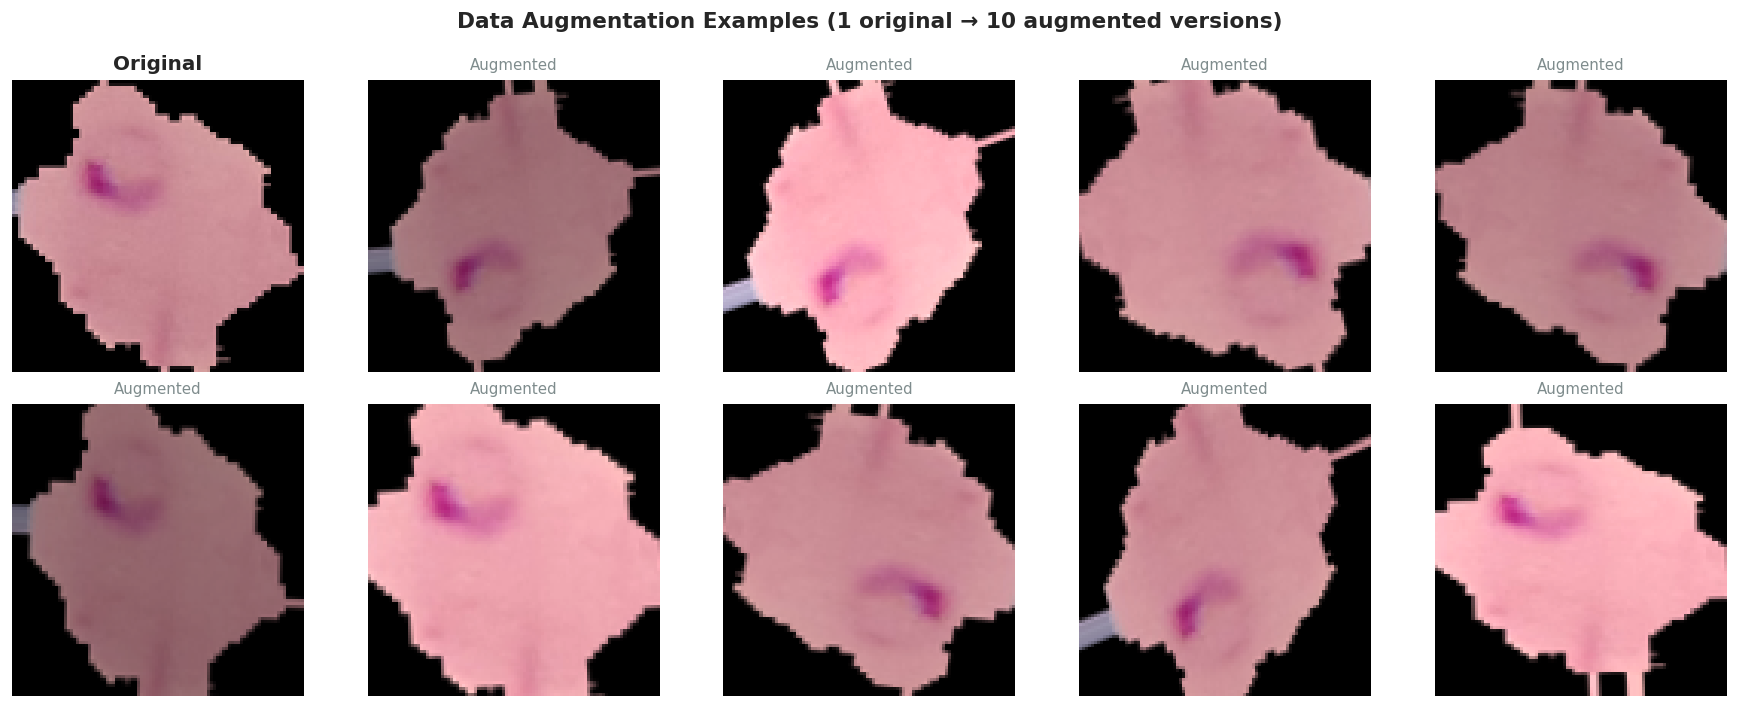

In [46]:
# ── Visualisation 6: Augmented Samples ───────────────────
aug_datagen = ImageDataGenerator(
    rotation_range=20, zoom_range=0.15,
    horizontal_flip=True, vertical_flip=True,
    brightness_range=[0.7, 1.3], fill_mode='nearest'
)

sample_img_path = os.path.join(DATA_DIR, 'Parasitized', parasitized_imgs[0])
sample_img      = np.array(Image.open(sample_img_path).convert('RGB').resize(IMG_SIZE))
sample_img_exp  = np.expand_dims(sample_img, 0)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Data Augmentation Examples (1 original → 10 augmented versions)',
             fontsize=13, fontweight='bold')
axes[0, 0].imshow(sample_img); axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')

aug_iter = aug_datagen.flow(sample_img_exp, batch_size=1)
plot_positions = [(0,1),(0,2),(0,3),(0,4),(1,0),(1,1),(1,2),(1,3),(1,4)]
for (r,c) in plot_positions:
    aug_img = next(aug_iter)[0].astype('uint8')
    axes[r,c].imshow(aug_img); axes[r,c].set_title('Augmented', color='#7F8C8D', fontsize=9)
    axes[r,c].axis('off')

plt.tight_layout()
plt.savefig('viz_augmentation.png', bbox_inches='tight')
plt.show()

## 5. Model — MobileNetV2 with Transfer Learning

**Strategy (2-phase training):**
1. **Phase 1 — Head only:** Freeze the MobileNetV2 base, train only the new classification head. Fast (5 epochs).
2. **Phase 2 — Fine-tuning:** Unfreeze the last 30 layers of the base and train with a very low learning rate. Achieves better accuracy.

In [47]:
def build_model(input_shape=(96, 96, 3)):
    # Load MobileNetV2 without top classification layers
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Freeze base initially

    # Build new classification head
    inputs  = tf.keras.Input(shape=input_shape)
    x       = base_model(inputs, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dense(128, activation='relu')(x)
    x       = layers.Dropout(0.4)(x)
    x       = layers.Dense(64, activation='relu')(x)
    x       = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs, name='malaria_mobilenetv2')
    return model, base_model

model, base_model = build_model(input_shape=IMG_SIZE + (3,))
model.summary()

print(f"\nTotal params      : {model.count_params():,}")
print(f"Trainable params  : {sum([tf.size(w).numpy() for w in model.trainable_weights]):,}")
print(f"Base model layers : {len(base_model.layers)}")

Model: "malaria_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,435,393 (9.29 MB)

 Trainable params: 174,849 (683.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)


Total params      : 2,435,393
Trainable params  : 174,849
Base model layers : 154


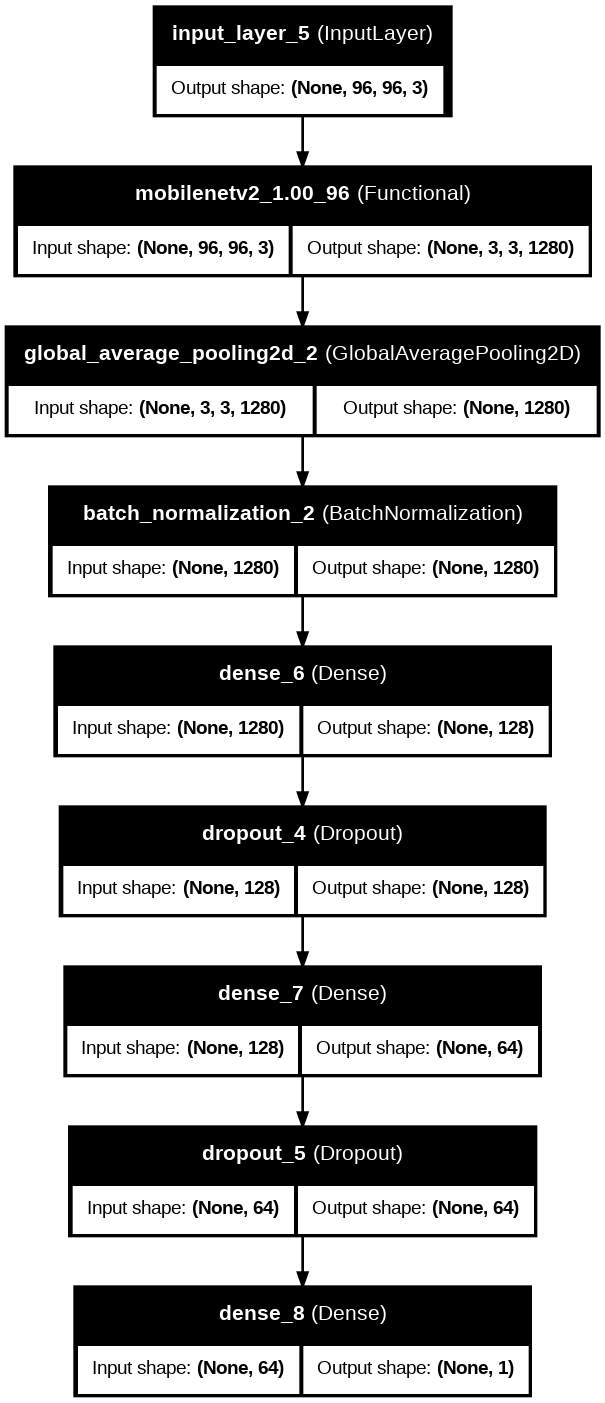

In [48]:
# ── Visualisation 7: Model Architecture Summary Plot ─────
tf.keras.utils.plot_model(
    model,
    to_file='viz_model_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    rankdir='TB',
    dpi=96
)
from IPython.display import Image as IPImage
IPImage('viz_model_architecture.png', width=400)

## 6. Phase 1 — Train Classification Head

In [49]:
model.compile(
    optimizer=Adam(learning_rate=LR_HEAD),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

callbacks_phase1 = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

print("Phase 1: Training head only (base frozen)...")
history1 = model.fit(
    train_gen,
    epochs=EPOCHS_HEAD,
    validation_data=val_gen,
    callbacks=callbacks_phase1,
    verbose=1
)

Phase 1: Training head only (base frozen)...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1775753178.098490     176 service.cc:152] XLA service 0x7869ac014870 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775753178.098531     176 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1775753178.098535     176 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1775753179.492239     176 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-09 16:46:28.178372: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-09 16:46:28.313307: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-09 16:46:28.450546: E external/local_xl

164/345 ━━━━━━━━━━━━━━━━━━━━ 1:52 621ms/step - accuracy: 0.8188 - auc: 0.8958 - loss: 0.4014 - precision: 0.8164 - recall: 0.8299

2026-04-09 16:48:21.551315: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-09 16:48:21.688492: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


345/345 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - accuracy: 0.8471 - auc: 0.9211 - loss: 0.3515 - precision: 0.8416 - recall: 0.8585

2026-04-09 16:51:41.682319: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-09 16:51:41.836555: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-09 16:51:41.972320: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-09 16:51:42.107332: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


345/345 ━━━━━━━━━━━━━━━━━━━━ 333s 909ms/step - accuracy: 0.8472 - auc: 0.9212 - loss: 0.3513 - precision: 0.8417 - recall: 0.8586 - val_accuracy: 0.9250 - val_auc: 0.9766 - val_loss: 0.1996 - val_precision: 0.9024 - val_recall: 0.9532 - learning_rate: 0.0010
Epoch 2/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 129s 374ms/step - accuracy: 0.9072 - auc: 0.9635 - loss: 0.2466 - precision: 0.9014 - recall: 0.9139 - val_accuracy: 0.9094 - val_auc: 0.9756 - val_loss: 0.2255 - val_precision: 0.8660 - val_recall: 0.9688 - learning_rate: 0.0010
Epoch 3/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 0.9213 - auc: 0.9718 - loss: 0.2139 - precision: 0.9137 - recall: 0.9306
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
345/345 ━━━━━━━━━━━━━━━━━━━━ 140s 406ms/step - accuracy: 0.9213 - auc: 0.9718 - loss: 0.2139 - precision: 0.9137 - recall: 0.9306 - val_accuracy: 0.9174 - val_auc: 0.9748 - val_loss: 0.2113 - val_precision: 0.8808 - val_recall: 0.9655 - learning_rate: 0.00

## 7. Phase 2 — Fine-tune Last Layers of Base

In [50]:
# Unfreeze last 30 layers of MobileNetV2
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

trainable_now = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f"Trainable params after unfreezing: {trainable_now:,}")

model.compile(
    optimizer=Adam(learning_rate=LR_FINE),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

callbacks_phase2 = [
    EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, verbose=1),
    ModelCheckpoint(MODEL_PATH, monitor='val_accuracy', save_best_only=True, verbose=1)
]

print("\nPhase 2: Fine-tuning last 30 base layers...")
history2 = model.fit(
    train_gen,
    epochs=EPOCHS_FINE,
    validation_data=val_gen,
    callbacks=callbacks_phase2,
    verbose=1
)

# Merge histories
def merge_histories(h1, h2):
    merged = {}
    for key in h1.history:
        merged[key] = h1.history[key] + h2.history[key]
    return merged

full_history = merge_histories(history1, history2)
with open(HISTORY_PATH, 'w') as f:
    json.dump(full_history, f)

Trainable params after unfreezing: 1,701,249

Phase 2: Fine-tuning last 30 base layers...
Epoch 1/45
345/345 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.9027 - auc: 0.9618 - loss: 0.2567 - precision: 0.9114 - recall: 0.8933
Epoch 1: val_accuracy improved from -inf to 0.89764, saving model to malaria_mobilenetv2.keras
345/345 ━━━━━━━━━━━━━━━━━━━━ 137s 345ms/step - accuracy: 0.9027 - auc: 0.9618 - loss: 0.2566 - precision: 0.9114 - recall: 0.8933 - val_accuracy: 0.8976 - val_auc: 0.9720 - val_loss: 0.3052 - val_precision: 0.8429 - val_recall: 0.9775 - learning_rate: 1.0000e-05
Epoch 2/45
345/345 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9268 - auc: 0.9735 - loss: 0.2082 - precision: 0.9198 - recall: 0.9346
Epoch 2: val_accuracy did not improve from 0.89764
345/345 ━━━━━━━━━━━━━━━━━━━━ 102s 297ms/step - accuracy: 0.9268 - auc: 0.9735 - loss: 0.2081 - precision: 0.9198 - recall: 0.9346 - val_accuracy: 0.8877 - val_auc: 0.9701 - val_loss: 0.3294 - val_precision: 0.8266 - val_rec

## 8. Training Visualisations

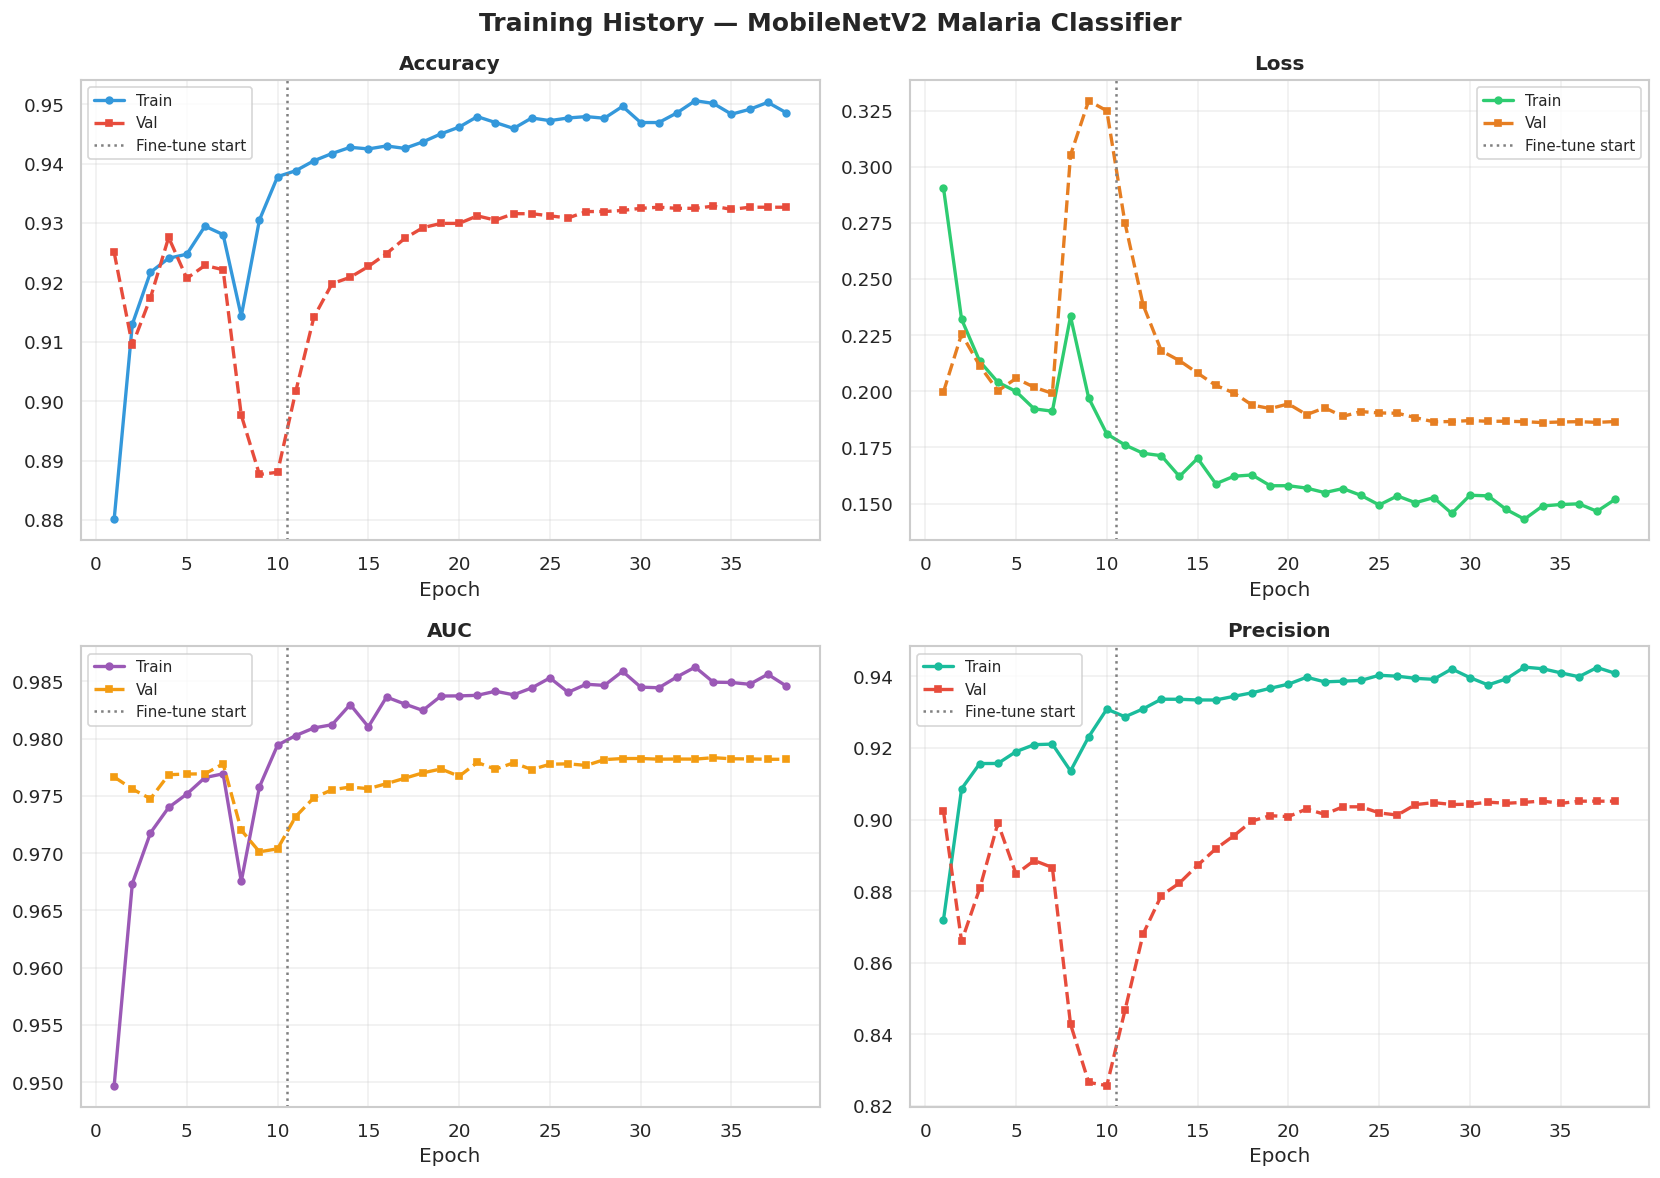

In [51]:
with open(HISTORY_PATH) as f:
    hist = json.load(f)

epochs_total = len(hist['accuracy'])
ep = range(1, epochs_total + 1)
phase_split = EPOCHS_HEAD  # vertical line between phase 1 & 2

# ── Visualisation 8: Training curves (4-panel) ───────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Training History — MobileNetV2 Malaria Classifier', fontsize=15, fontweight='bold')

metrics = [
    ('accuracy',  'val_accuracy',  'Accuracy',  '#3498DB', '#E74C3C'),
    ('loss',      'val_loss',      'Loss',       '#2ECC71', '#E67E22'),
    ('auc',       'val_auc',       'AUC',        '#9B59B6', '#F39C12'),
    ('precision', 'val_precision', 'Precision',  '#1ABC9C', '#E74C3C'),
]

for ax, (train_key, val_key, title, tc, vc) in zip(axes.flat, metrics):
    ax.plot(ep, hist[train_key], marker='o', markersize=4, color=tc, label='Train', lw=2)
    ax.plot(ep, hist[val_key],   marker='s', markersize=4, color=vc, label='Val',   lw=2, ls='--')
    ax.axvline(phase_split + 0.5, color='gray', linestyle=':', lw=1.5, label='Fine-tune start')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('viz_training_curves.png', bbox_inches='tight')
plt.show()

## 9. Evaluation

In [52]:
# Load best saved model
model = tf.keras.models.load_model(MODEL_PATH)

val_gen.reset()
loss, acc, auc_score, prec, rec = model.evaluate(val_gen, verbose=1)
f1 = 2 * prec * rec / (prec + rec + 1e-8)

print(f"\n{'='*40}")
print(f"  Validation Accuracy  : {acc*100:.2f}%")
print(f"  Validation AUC       : {auc_score:.4f}")
print(f"  Precision            : {prec:.4f}")
print(f"  Recall               : {rec:.4f}")
print(f"  F1 Score             : {f1:.4f}")
print(f"{'='*40}")

87/87 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.9065 - auc: 0.5001 - loss: 0.2375 - precision: 0.3935 - recall: 0.4973

  Validation Accuracy  : 93.28%
  Validation AUC       : 0.9783
  Precision            : 0.9052
  Recall               : 0.9670
  F1 Score             : 0.9351


In [53]:
# Get predictions
val_gen.reset()
pred_probs  = model.predict(val_gen, verbose=1).flatten()
pred_labels = (pred_probs > 0.5).astype(int)
true_labels = val_gen.classes
class_names_ordered = list(val_gen.class_indices.keys())

87/87 ━━━━━━━━━━━━━━━━━━━━ 16s 139ms/step


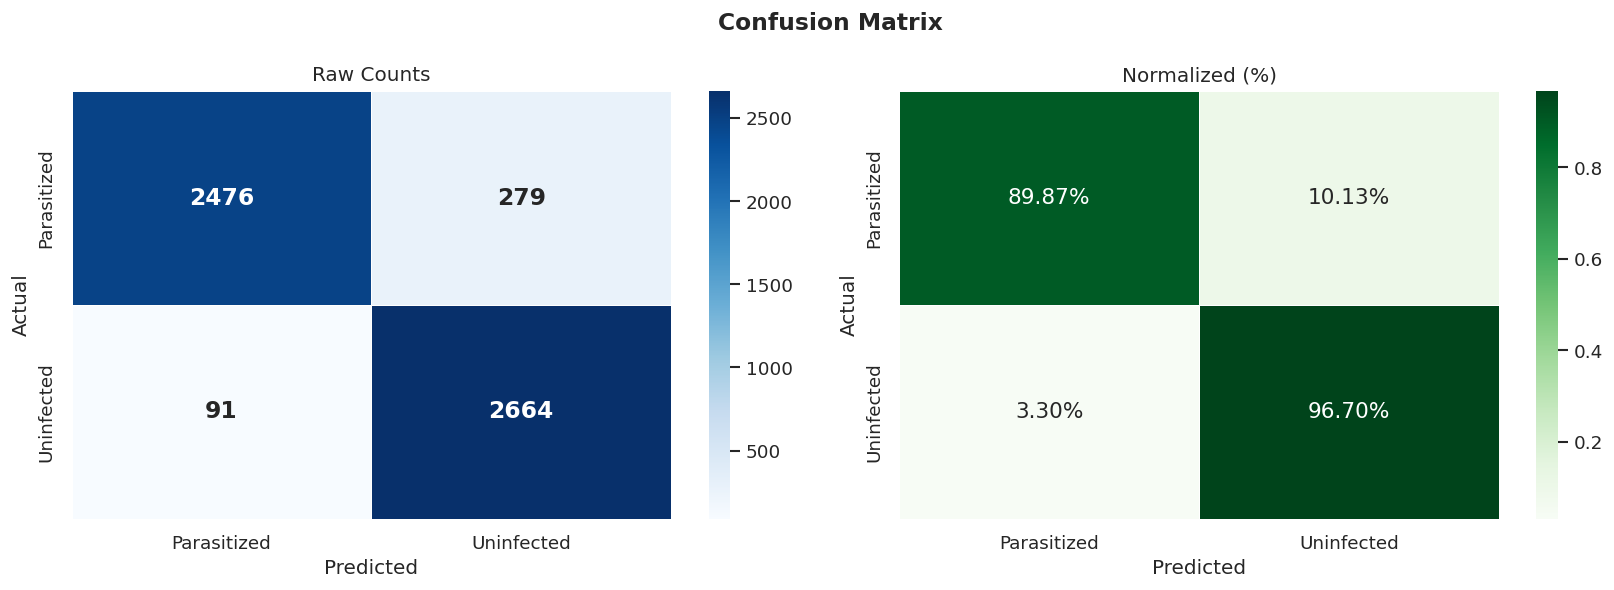


Classification Report:

              precision    recall  f1-score   support

 Parasitized       0.96      0.90      0.93      2755
  Uninfected       0.91      0.97      0.94      2755

    accuracy                           0.93      5510
   macro avg       0.93      0.93      0.93      5510
weighted avg       0.93      0.93      0.93      5510



In [54]:
# ── Visualisation 9: Confusion Matrix ────────────────────
cm = confusion_matrix(true_labels, pred_labels)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrix', fontsize=14, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names_ordered, yticklabels=class_names_ordered,
            linewidths=0.5, annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Raw Counts'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1],
            xticklabels=class_names_ordered, yticklabels=class_names_ordered,
            linewidths=0.5, annot_kws={'size': 13})
axes[1].set_title('Normalized (%)'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('viz_confusion_matrix.png', bbox_inches='tight')
plt.show()

print("\nClassification Report:\n")
print(classification_report(true_labels, pred_labels, target_names=class_names_ordered))

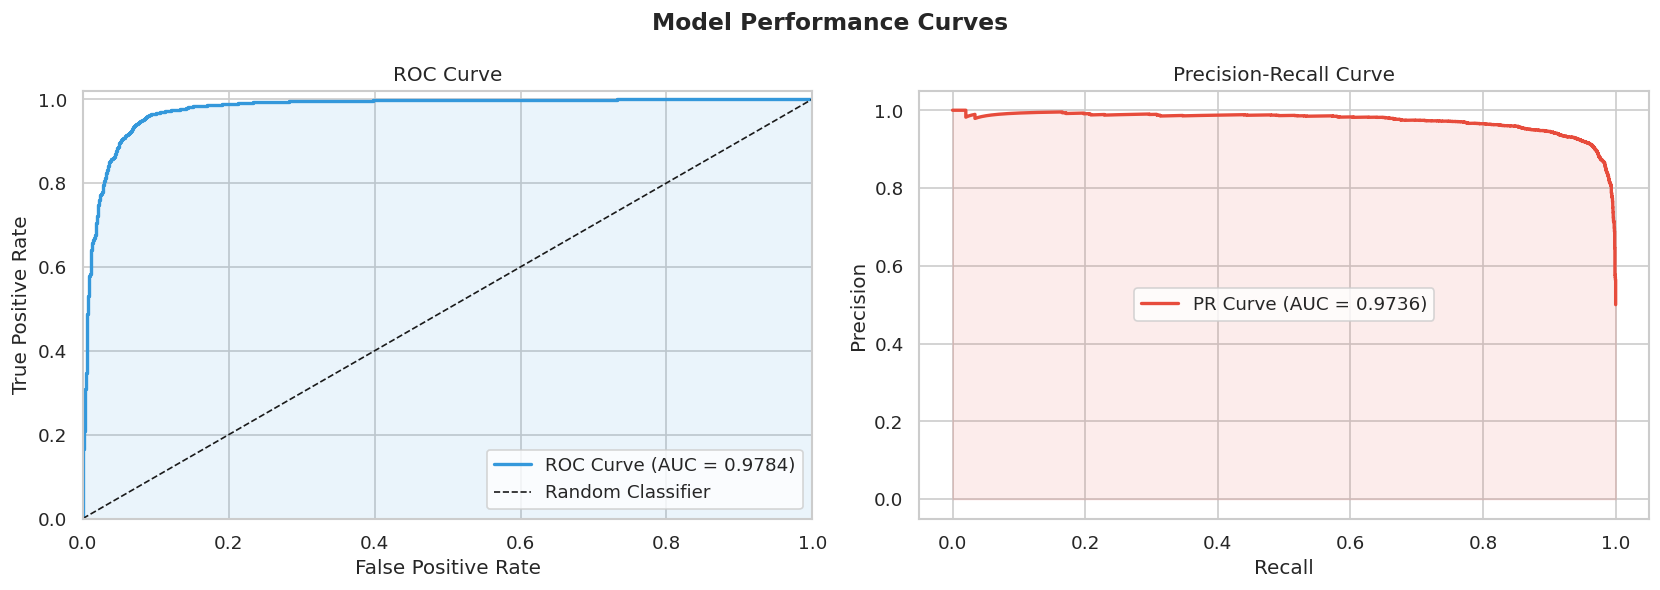

In [55]:
# ── Visualisation 10: ROC Curve ───────────────────────────
fpr, tpr, thresholds = roc_curve(true_labels, pred_probs)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Performance Curves', fontsize=14, fontweight='bold')

# ROC
axes[0].plot(fpr, tpr, color='#3498DB', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0,1],[0,1], 'k--', lw=1, label='Random Classifier')
axes[0].fill_between(fpr, tpr, alpha=0.1, color='#3498DB')
axes[0].set_title('ROC Curve'); axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate'); axes[0].legend(loc='lower right')
axes[0].set_xlim([0,1]); axes[0].set_ylim([0,1.02])

# Precision-Recall
prec_curve, rec_curve, _ = precision_recall_curve(true_labels, pred_probs)
pr_auc = auc(rec_curve, prec_curve)
axes[1].plot(rec_curve, prec_curve, color='#E74C3C', lw=2, label=f'PR Curve (AUC = {pr_auc:.4f})')
axes[1].fill_between(rec_curve, prec_curve, alpha=0.1, color='#E74C3C')
axes[1].set_title('Precision-Recall Curve'); axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision'); axes[1].legend()

plt.tight_layout()
plt.savefig('viz_roc_pr_curves.png', bbox_inches='tight')
plt.show()

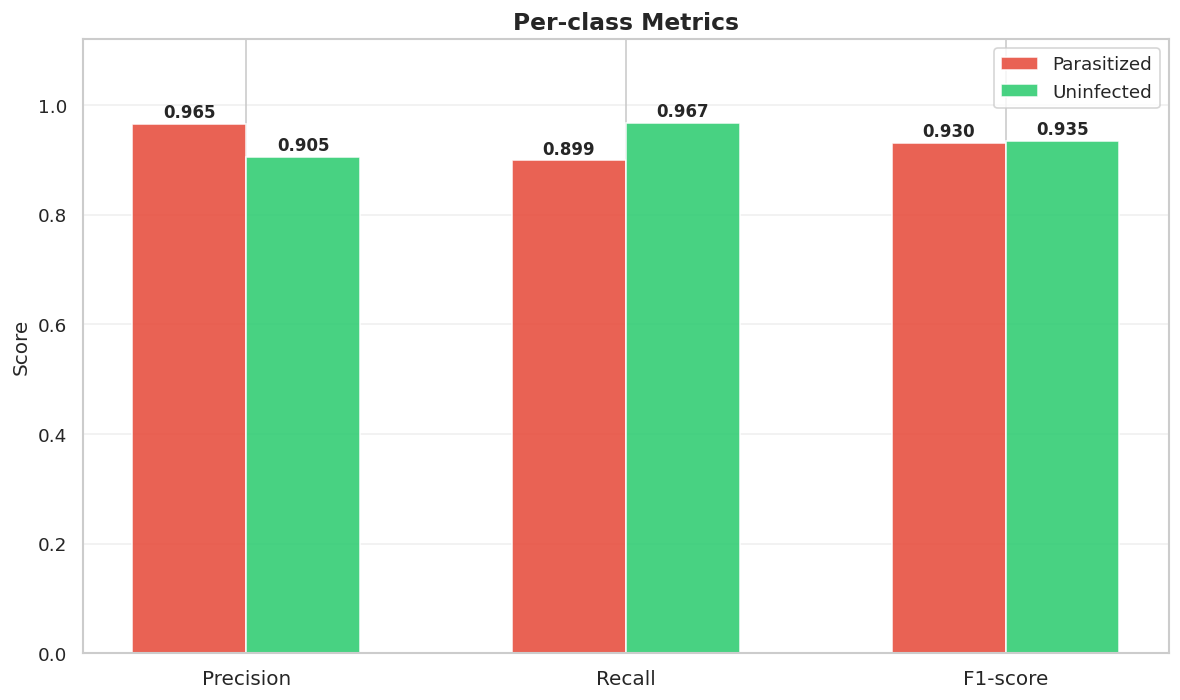

In [56]:
# ── Visualisation 11: Metrics Summary Bar ─────────────────
report = classification_report(true_labels, pred_labels,
                                target_names=class_names_ordered, output_dict=True)
metric_names = ['precision', 'recall', 'f1-score']
classes_plot = class_names_ordered

x = np.arange(len(metric_names))
width = 0.3
colors_bar = ['#E74C3C', '#2ECC71']

fig, ax = plt.subplots(figsize=(10, 6))
for i, cls in enumerate(classes_plot):
    vals = [report[cls][m] for m in metric_names]
    bars = ax.bar(x + i*width, vals, width, label=cls, color=colors_bar[i],
                  edgecolor='white', alpha=0.88)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(x + width/2); ax.set_xticklabels([m.capitalize() for m in metric_names], fontsize=12)
ax.set_ylim(0, 1.12); ax.set_title('Per-class Metrics', fontsize=14, fontweight='bold')
ax.set_ylabel('Score'); ax.legend(fontsize=11); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_metrics_bar.png', bbox_inches='tight')
plt.show()

/tmp/ipykernel_55/237809531.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_box, labels=['Parasitized', 'Uninfected'],


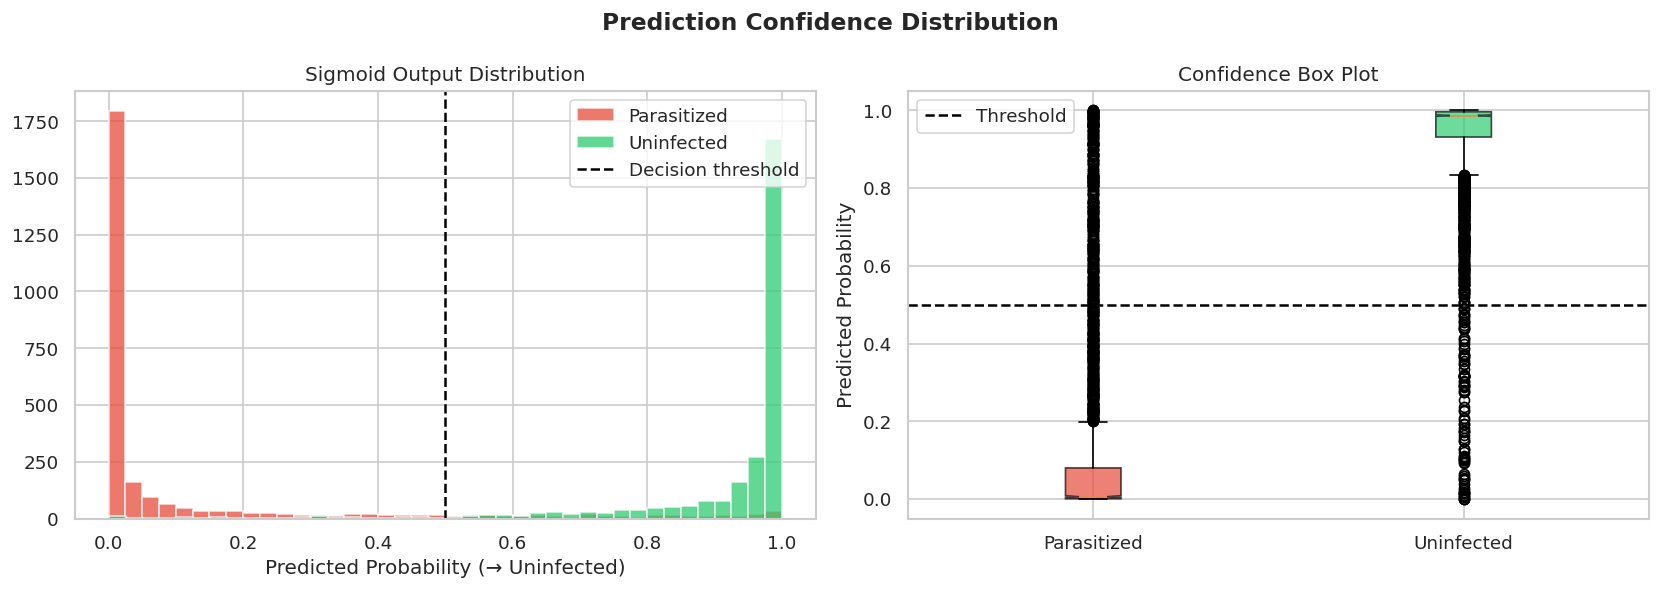

In [57]:
# ── Visualisation 12: Confidence Score Distribution ───────
para_mask  = true_labels == 0   # Parasitized index (check class_indices)
uninf_mask = true_labels == 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Prediction Confidence Distribution', fontsize=14, fontweight='bold')

axes[0].hist(pred_probs[para_mask],  bins=40, color='#E74C3C', alpha=0.75,
             edgecolor='white', label='Parasitized')
axes[0].hist(pred_probs[uninf_mask], bins=40, color='#2ECC71', alpha=0.75,
             edgecolor='white', label='Uninfected')
axes[0].axvline(0.5, color='black', linestyle='--', lw=1.5, label='Decision threshold')
axes[0].set_title('Sigmoid Output Distribution')
axes[0].set_xlabel('Predicted Probability (→ Uninfected)'); axes[0].legend()

# Box plot of confidence by class
data_box = [pred_probs[para_mask], pred_probs[uninf_mask]]
bp = axes[1].boxplot(data_box, labels=['Parasitized', 'Uninfected'],
                     patch_artist=True, notch=True)
for patch, color in zip(bp['boxes'], ['#E74C3C', '#2ECC71']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].axhline(0.5, color='black', linestyle='--', lw=1.5, label='Threshold')
axes[1].set_title('Confidence Box Plot'); axes[1].set_ylabel('Predicted Probability'); axes[1].legend()

plt.tight_layout()
plt.savefig('viz_confidence_distribution.png', bbox_inches='tight')
plt.show()

Correct predictions : 5,140
Wrong predictions   : 370
Error rate          : 6.72%


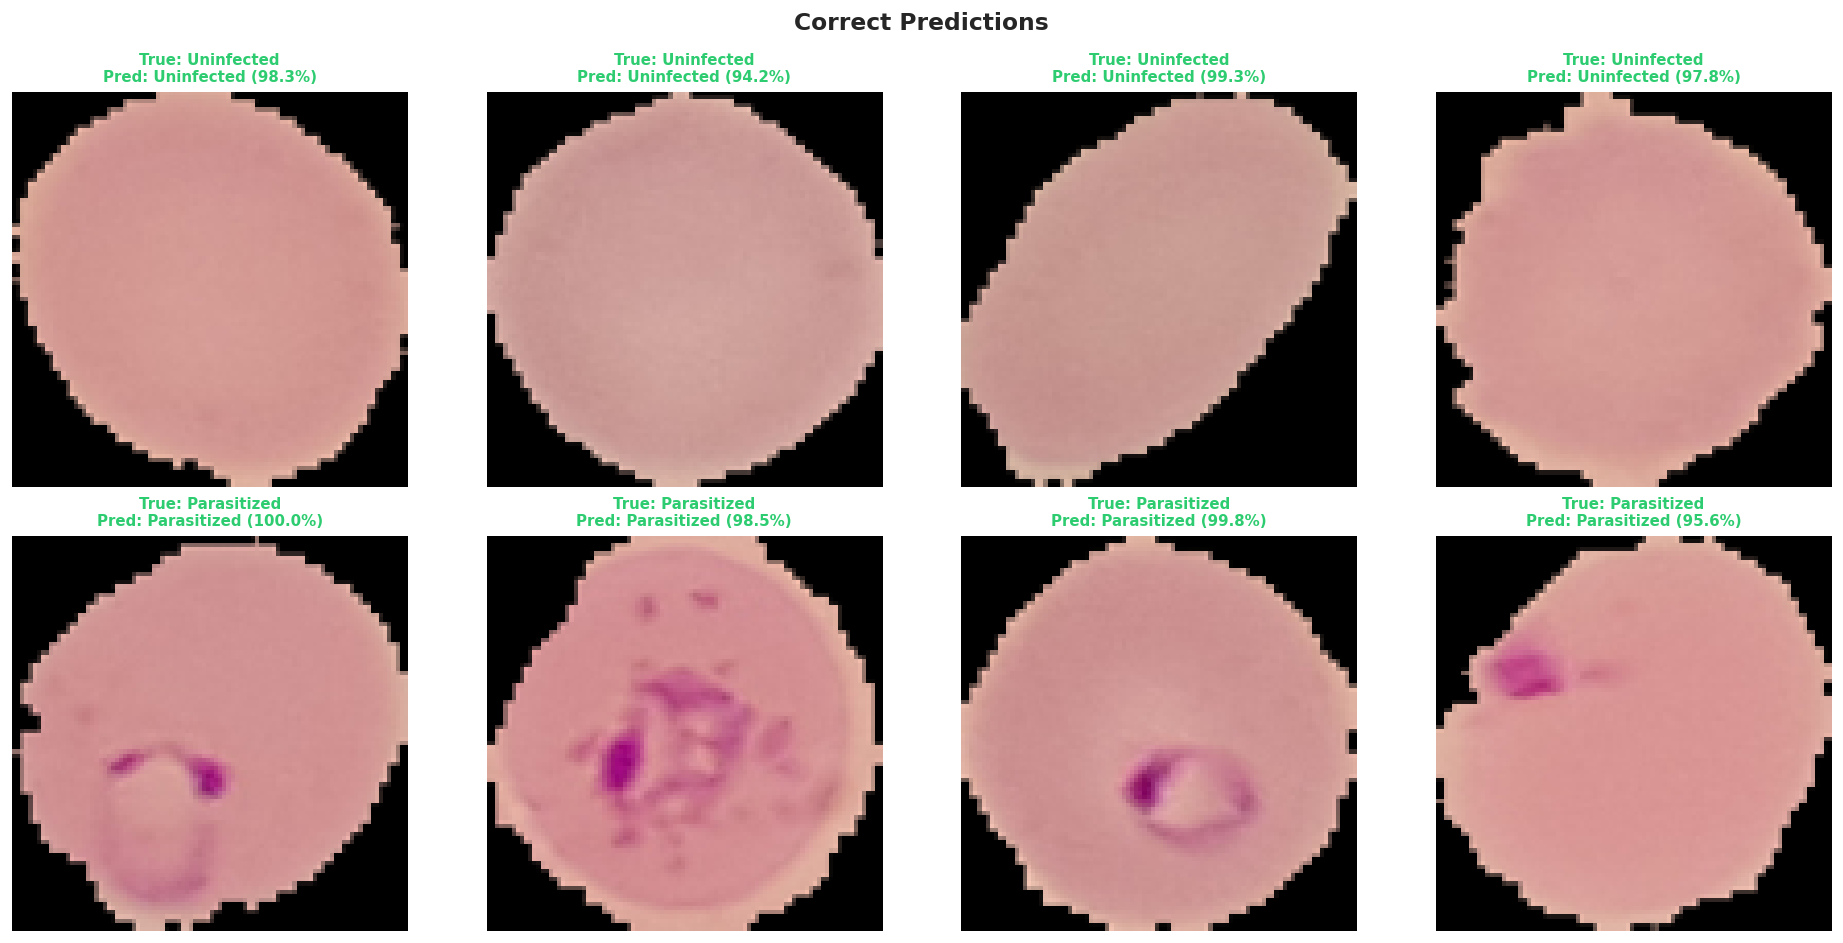

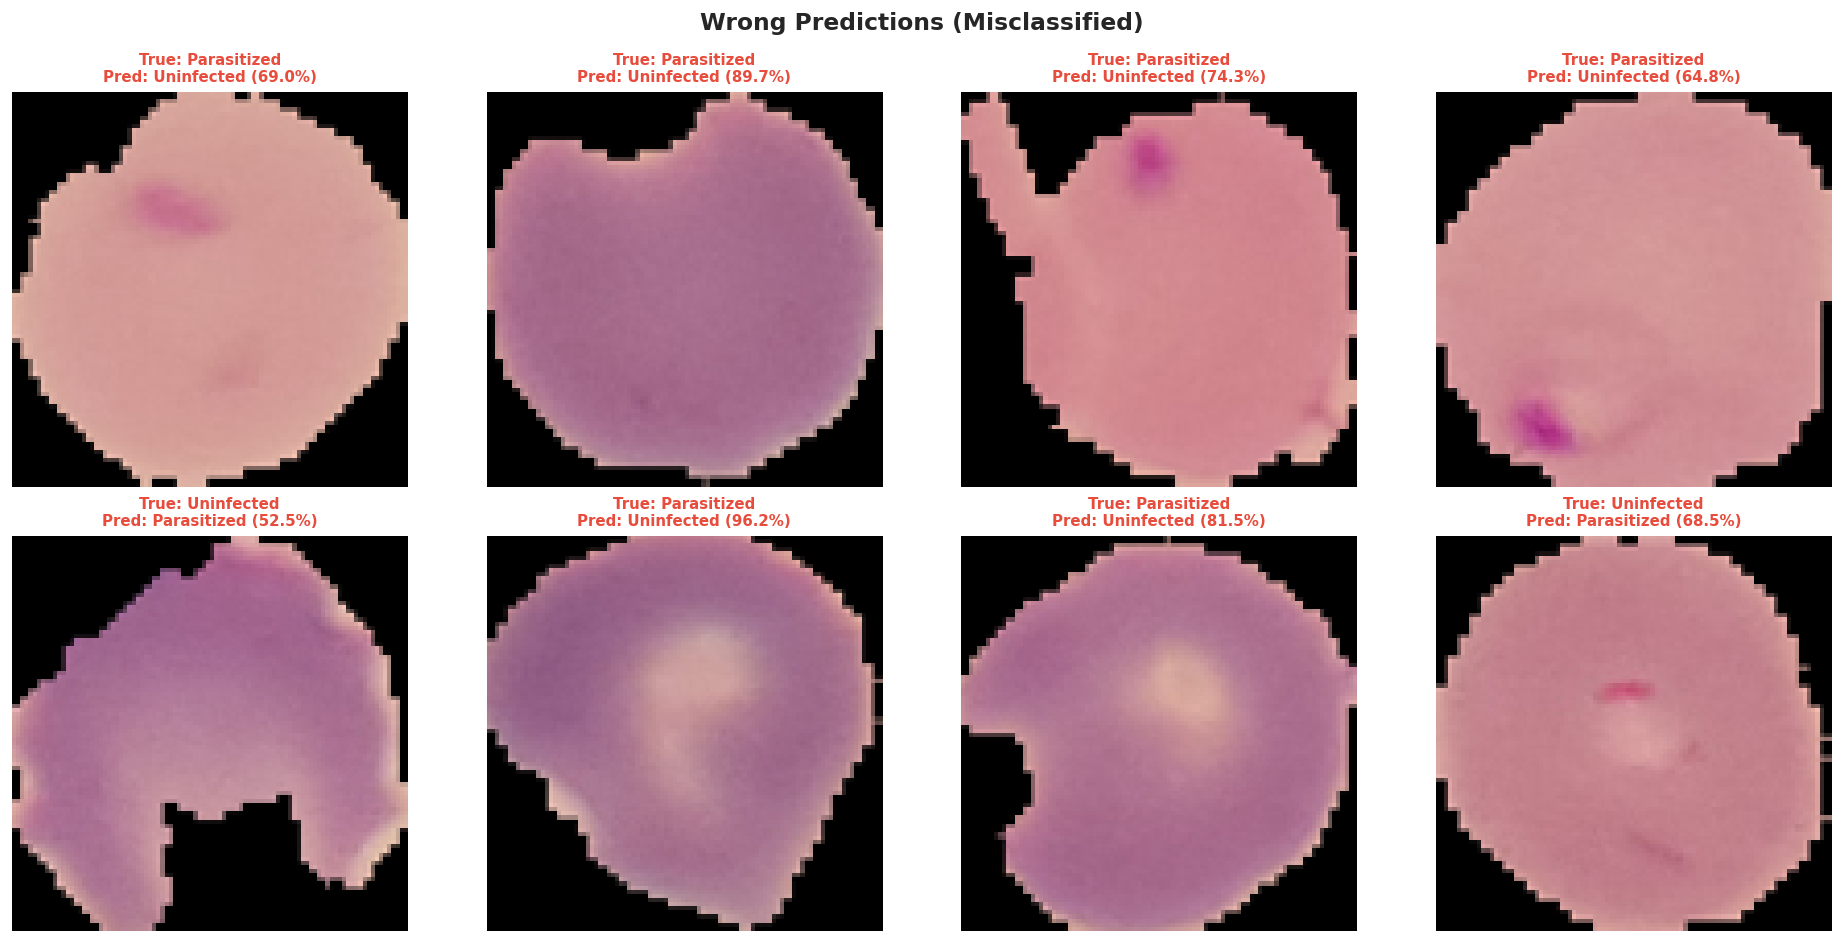

In [58]:
# ── Visualisation 13: Correct vs Wrong Predictions ────────
val_gen.reset()
filepaths = val_gen.filepaths

wrong_idx   = np.where(pred_labels != true_labels)[0]
correct_idx = np.where(pred_labels == true_labels)[0]

print(f"Correct predictions : {len(correct_idx):,}")
print(f"Wrong predictions   : {len(wrong_idx):,}")
print(f"Error rate          : {len(wrong_idx)/len(true_labels)*100:.2f}%")

def show_predictions(indices, title, n=8):
    sample = random.sample(list(indices), min(n, len(indices)))
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    for ax, idx in zip(axes.flat, sample):
        img = Image.open(filepaths[idx]).convert('RGB').resize(IMG_SIZE)
        ax.imshow(img)
        true_cls = class_names_ordered[true_labels[idx]]
        pred_cls = class_names_ordered[pred_labels[idx]]
        conf     = pred_probs[idx] if pred_labels[idx] == 1 else 1 - pred_probs[idx]
        color    = '#2ECC71' if true_cls == pred_cls else '#E74C3C'
        ax.set_title(f'True: {true_cls}\nPred: {pred_cls} ({conf:.1%})',
                     fontsize=9, color=color, fontweight='bold')
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'viz_{title.lower().replace(" ","_")}.png', bbox_inches='tight')
    plt.show()

show_predictions(correct_idx, 'Correct Predictions')
show_predictions(wrong_idx,   'Wrong Predictions (Misclassified)')

## 10. Grad-CAM Interpretability

In [59]:
# Find last conv layer in base model
last_conv_layer = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer; break
    if hasattr(layer, 'layers'):  # MobileNetV2 is a sub-model
        for sub_layer in reversed(layer.layers):
            if isinstance(sub_layer, tf.keras.layers.Conv2D):
                last_conv_layer = sub_layer; break
    if last_conv_layer: break

print("Grad-CAM target layer:", last_conv_layer.name)

grad_model = tf.keras.Model(
    inputs=model.input,
    outputs=[last_conv_layer.output, model.output]
)

def make_gradcam(img_path):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_tensor = tf.convert_to_tensor(np.expand_dims(img_array / 255.0, 0), dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(img_tensor)
        conv_outputs, predictions = grad_model(img_tensor)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(tf.multiply(pooled_grads, conv_outputs[0]), axis=-1)
    heatmap = np.maximum(heatmap.numpy(), 0)
    heatmap = heatmap / (heatmap.max() + 1e-8)
    heatmap = cv2.resize(heatmap, IMG_SIZE)

    orig = cv2.resize(cv2.imread(img_path), IMG_SIZE)
    heat_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(orig, 0.55, heat_color, 0.45, 0)
    return np.array(img), cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB), predictions.numpy()[0][0]

print("Grad-CAM ready.")

Grad-CAM target layer: Conv_1
Grad-CAM ready.


KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m132398953702864\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 96, 96, 3), dtype=float32)\n  • training=None\n  • mask=None\n  • kwargs=<class 'inspect._empty'>"

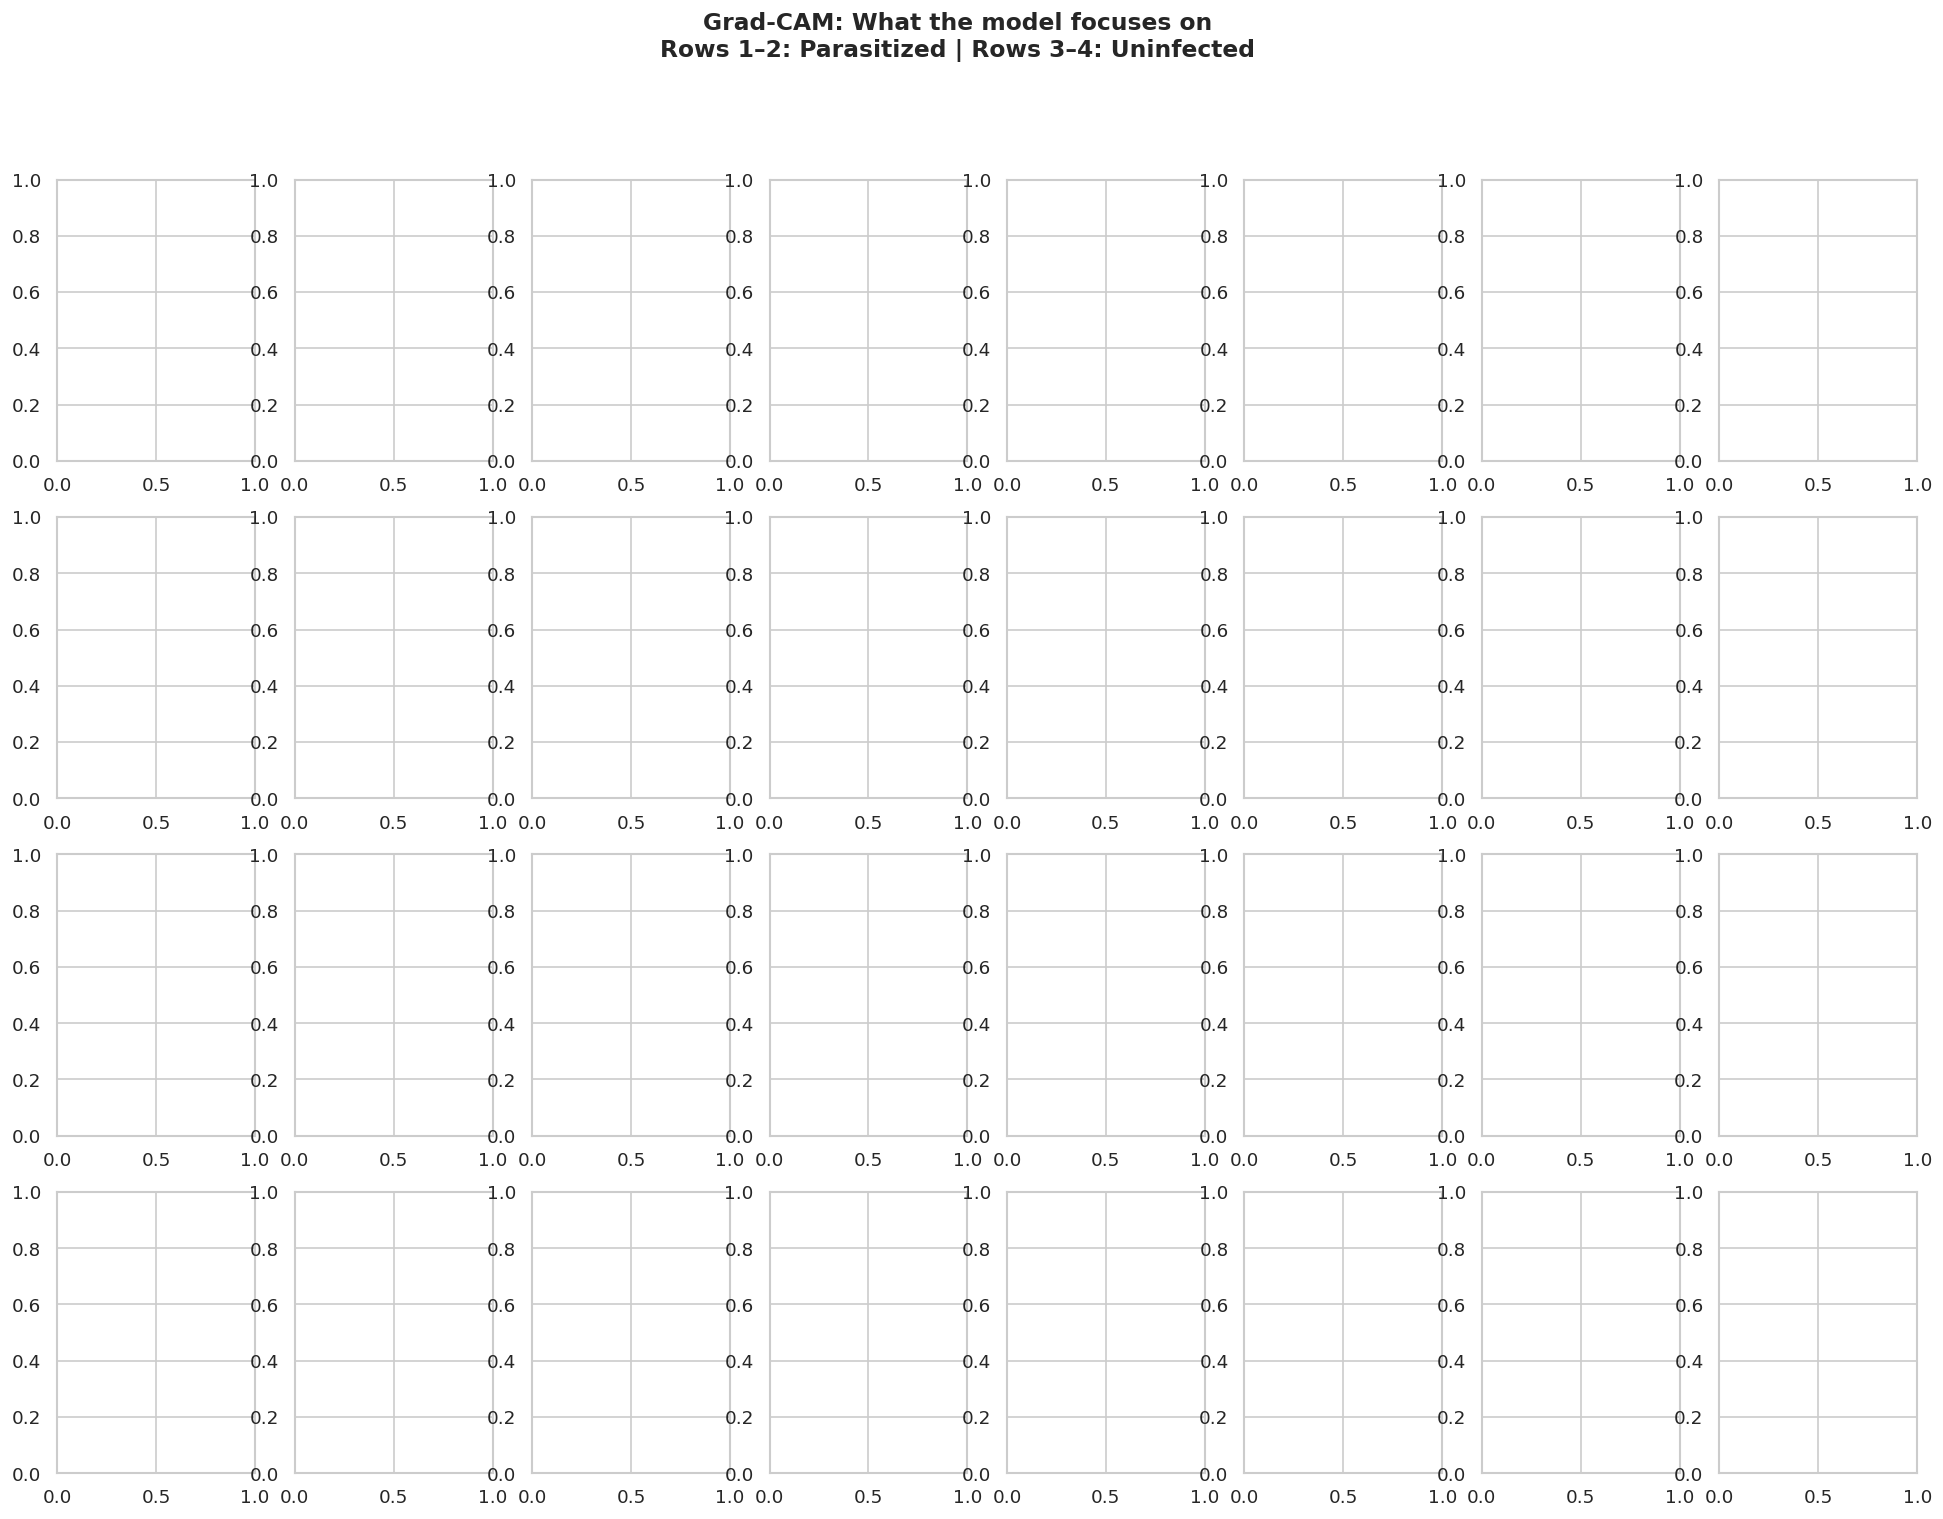

In [60]:
# ── Visualisation 14: Grad-CAM Grid ─────────────────────
n_show = 4
para_samples  = [filepaths[i] for i in random.sample(list(np.where(true_labels==0)[0]), n_show)]
uninf_samples = [filepaths[i] for i in random.sample(list(np.where(true_labels==1)[0]), n_show)]

fig, axes = plt.subplots(4, n_show*2, figsize=(20, 14))
fig.suptitle('Grad-CAM: What the model focuses on\n'
             'Rows 1–2: Parasitized | Rows 3–4: Uninfected', fontsize=14, fontweight='bold')

for col, path in enumerate(para_samples):
    orig, overlay, prob = make_gradcam(path)
    pred = 'Uninfected' if prob > 0.5 else 'Parasitized'
    axes[0, col*2].imshow(orig); axes[0, col*2].set_title('Original\n(Infected)', color='#E74C3C', fontsize=9); axes[0, col*2].axis('off')
    axes[1, col*2].imshow(overlay); axes[1, col*2].set_title(f'Grad-CAM\nPred: {pred} ({1-prob:.1%})', fontsize=9); axes[1, col*2].axis('off')
    axes[0, col*2+1].axis('off'); axes[1, col*2+1].axis('off')

for col, path in enumerate(uninf_samples):
    orig, overlay, prob = make_gradcam(path)
    pred = 'Uninfected' if prob > 0.5 else 'Parasitized'
    axes[2, col*2].imshow(orig); axes[2, col*2].set_title('Original\n(Healthy)', color='#2ECC71', fontsize=9); axes[2, col*2].axis('off')
    axes[3, col*2].imshow(overlay); axes[3, col*2].set_title(f'Grad-CAM\nPred: {pred} ({prob:.1%})', fontsize=9); axes[3, col*2].axis('off')
    axes[2, col*2+1].axis('off'); axes[3, col*2+1].axis('off')

plt.tight_layout()
plt.savefig('viz_gradcam.png', bbox_inches='tight')
plt.show()

## 11. Summary Dashboard

In [ ]:
# ── Visualisation 16: Final Summary Dashboard ─────────────
fig = plt.figure(figsize=(16, 10))
fig.suptitle('Malaria Cell Classifier — MobileNetV2 Results Summary', fontsize=16, fontweight='bold', y=1.01)

# Metric cards
metric_vals = [acc*100, auc_score*100, prec*100, rec*100, f1*100]
metric_labels = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score']
colors_card = ['#3498DB','#9B59B6','#2ECC71','#E74C3C','#F39C12']

for i, (val, label, col) in enumerate(zip(metric_vals, metric_labels, colors_card)):
    ax = fig.add_subplot(3, 5, i+1)
    ax.set_facecolor(col)
    ax.text(0.5, 0.6, f'{val:.1f}%', ha='center', va='center',
            fontsize=22, fontweight='bold', color='white', transform=ax.transAxes)
    ax.text(0.5, 0.2, label, ha='center', va='center',
            fontsize=11, color='white', transform=ax.transAxes)
    ax.axis('off')

# Loss curve
ax2 = fig.add_subplot(3, 2, 3)
ax2.plot(ep, hist['loss'], label='Train Loss', color='#3498DB', lw=2)
ax2.plot(ep, hist['val_loss'], label='Val Loss', color='#E74C3C', lw=2, ls='--')
ax2.axvline(phase_split+0.5, color='gray', ls=':', lw=1)
ax2.set_title('Loss Curve'); ax2.legend(); ax2.grid(alpha=0.3)

# Accuracy curve
ax3 = fig.add_subplot(3, 2, 4)
ax3.plot(ep, hist['accuracy'], label='Train Acc', color='#2ECC71', lw=2)
ax3.plot(ep, hist['val_accuracy'], label='Val Acc', color='#F39C12', lw=2, ls='--')
ax3.axvline(phase_split+0.5, color='gray', ls=':', lw=1)
ax3.set_title('Accuracy Curve'); ax3.legend(); ax3.grid(alpha=0.3)

# Confusion matrix
ax4 = fig.add_subplot(3, 2, 5)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax4,
            xticklabels=class_names_ordered, yticklabels=class_names_ordered)
ax4.set_title('Confusion Matrix'); ax4.set_xlabel('Predicted'); ax4.set_ylabel('Actual')

# ROC
ax5 = fig.add_subplot(3, 2, 6)
ax5.plot(fpr, tpr, color='#9B59B6', lw=2, label=f'AUC={roc_auc:.3f}')
ax5.plot([0,1],[0,1],'k--', lw=1)
ax5.fill_between(fpr, tpr, alpha=0.1, color='#9B59B6')
ax5.set_title('ROC Curve'); ax5.set_xlabel('FPR'); ax5.set_ylabel('TPR'); ax5.legend()

plt.tight_layout()
plt.savefig('viz_summary_dashboard.png', bbox_inches='tight', dpi=150)
plt.show()
print("\n✅ All visualisations saved. Ready for PPT!")